In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Reading and checking the dataset

In [3]:
df=pd.read_csv("netflix.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# To see all columns
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [5]:
#Renaming the listed in column to genres
df.rename(columns={'listed_in':'genre'},inplace=True)
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genre', 'description'],
      dtype='str')

In [6]:
#Dropping the show_id column as it may be of no use in the analysis

In [7]:
df.drop('show_id',axis=1,inplace=True)
df.columns

Index(['type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genre', 'description'],
      dtype='str')

In [8]:
# Checking for duplicates
df.duplicated().sum()

np.int64(0)

In [9]:
#Checking the missing values

In [10]:
df.isna().sum()   # another way df.isnull().sum()

type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
genre              0
description        0
dtype: int64

In [11]:
# Dropping the rows which have null values in date_added column as there are only 10 values

In [12]:
df.dropna(subset=['date_added'],inplace=True)
df['date_added'].isna().sum()


np.int64(0)

In [13]:
# Dropping the rows which have null values in rating column as there are only 4 values

In [14]:
df.dropna(subset=['rating'],inplace=True)
df['rating'].isna().sum()

np.int64(0)

In [15]:
# Dropping the rows which have null values in duration column as there are only 3 values

In [16]:
df=df.dropna(subset=['duration'])
df['duration'].isna().sum()

np.int64(0)

In [17]:
df.isnull().sum()

type               0
title              0
director        2621
cast             825
country          829
date_added         0
release_year       0
rating             0
duration           0
genre              0
description        0
dtype: int64

In [18]:
df.info()

<class 'pandas.DataFrame'>
Index: 8790 entries, 0 to 8806
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   type          8790 non-null   str  
 1   title         8790 non-null   str  
 2   director      6169 non-null   str  
 3   cast          7965 non-null   str  
 4   country       7961 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   genre         8790 non-null   str  
 10  description   8790 non-null   str  
dtypes: int64(1), str(10)
memory usage: 3.8 MB


In [19]:
# When there is some mismatch in our date format then that values is replaced by null
df['date_added']=pd.to_datetime(df['date_added'],errors='coerce')
df['date_added'].isna().sum()


np.int64(88)

In [20]:
df.dropna(subset=['date_added'],inplace=True)
df['date_added'].isna().sum()

np.int64(0)

In [21]:
# Adding day, month, year, month_name,day_name as seprated columns
df['day']=df['date_added'].dt.day
df['month']=df['date_added'].dt.month
df['year']=df['date_added'].dt.year
df['month_name']=df['date_added'].dt.month_name()
df['weekday']=df['date_added'].dt.day_name()
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",24,9,2021,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,24,9,2021,September,Friday


In [22]:
df['duration'].unique()


<ArrowStringArray>
[   '90 min', '2 Seasons',  '1 Season',    '91 min',   '125 min', '9 Seasons',
   '104 min',   '127 min', '4 Seasons',    '67 min',
 ...
    '43 min',   '200 min',   '196 min',   '167 min',   '178 min',   '228 min',
    '18 min',   '205 min',   '201 min',   '191 min']
Length: 219, dtype: str

In [23]:
s1='90 min'
int(s1.split()[0])

90

In [24]:
s1='13 Seasons'
int(s1.split()[0])

13

In [25]:
df['duration']=df['duration'].apply(lambda x:int(x.split()[0]))
df['duration'].unique()

array([ 90,   2,   1,  91, 125,   9, 104, 127,   4,  67,  94,   5, 161,
        61, 166, 147, 103,  97, 106, 111,   3, 110, 105,  96, 124, 116,
        98,  23, 115, 122,  99,  88, 100,   6, 102,  93,  95,  85,  83,
       113,  13, 182,  48, 145,  87,  92,  80, 117, 128, 119, 143, 114,
       118, 108,  63, 121, 142, 154, 120,  82, 109, 101,  86, 229,  76,
        89, 156, 112, 107, 129, 135, 136, 165, 150, 133,  70,  84, 140,
        78,   7,  64,  59, 139,  69, 148, 189, 141, 130, 138,  81, 132,
        10, 123,  65,  68,  66,  62,  74, 131,  39,  46,  38,   8,  17,
       126, 155, 159, 137,  12, 273,  36,  34,  77,  60,  49,  58,  72,
       204, 212,  25,  73,  29,  47,  32,  35,  71, 149,  33,  15,  54,
       224, 162,  37,  75,  79,  55, 158, 164, 173, 181, 185,  21,  24,
        51, 151,  42,  22, 134, 177,  52,  14,  53,  57,  28,  50,  26,
        45, 171,  27,  44, 146,  20, 157, 203,  41,  30, 194, 233, 237,
       230, 195, 253, 152, 190, 160, 208, 180, 144, 174, 170, 19

In [26]:
# Checking for unique values of rating and categorising them for better understanding
df['rating'].unique()

<ArrowStringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',       'NR',
 'TV-Y7-FV',       'UR']
Length: 14, dtype: str

In [27]:
df['rating']=df['rating'].replace(['TV-Y','TV-Y7',"G",'TV-G','PG','TV-PG','TV-Y7-FV'],'kids')
df['rating']=df['rating'].replace(['PG-13','TV-14'],'teens')
df['rating']=df['rating'].replace(['R','TV-MA','NC', 'NC-17'],'adults')
df['rating']=df['rating'].replace(['NR','UR'],np.nan)
df


,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,teens,90,Documentaries,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,adults,1,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,adults,1,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",24,9,2021,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,adults,2,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,24,9,2021,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8802,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,adults,158,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",20,11,2019,November,Wednesday
8803,TV Show,Zombie Dumb,NaN,NaN,NaN,2019-07-01,2018,kids,2,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g...",1,7,2019,July,Monday
8804,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,adults,88,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,1,11,2019,November,Friday
8805,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,kids,88,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",11,1,2020,January,Saturday


In [28]:
df['rating'].unique()

<ArrowStringArray>
['teens', 'adults', 'kids', nan]
Length: 4, dtype: str

In [29]:
df['rating'].isnull().sum()

np.int64(81)

In [30]:
df.dropna(subset=['rating'],inplace=True)


In [31]:
df['rating'].isnull().sum()

np.int64(0)

In [32]:
df.isna().sum()

type               0
title              0
director        2535
cast             800
country          826
date_added         0
release_year       0
rating             0
duration           0
genre              0
description        0
day                0
month              0
year               0
month_name         0
weekday            0
dtype: int64

In [33]:
# Now we still have about 48% missing data .So, we will check in which rows the director, country and cast all three are null, if all these 3 are null then there is no use of that row


In [34]:
df[(df['director'].isna())&(df['country'].isna())&(df['cast'].isna())]

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,day,month,year,month_name,weekday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,adults,1,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",24,9,2021,September,Friday
10,TV Show,"Vendetta: Truth, Lies and The Mafia",NaN,NaN,NaN,2021-09-24,2021,adults,1,"Crime TV Shows, Docuseries, International TV S...","Sicily boasts a bold ""Anti-Mafia"" coalition. B...",24,9,2021,September,Friday
14,TV Show,Crime Stories: India Detectives,NaN,NaN,NaN,2021-09-22,2021,adults,1,"British TV Shows, Crime TV Shows, Docuseries",Cameras following Bengaluru police on the job ...,22,9,2021,September,Wednesday
74,TV Show,The World's Most Amazing Vacation Rentals,NaN,NaN,NaN,2021-09-14,2021,kids,2,Reality TV,"With an eye for every budget, three travelers ...",14,9,2021,September,Tuesday
123,TV Show,Luv Kushh,NaN,NaN,NaN,2021-09-02,2012,kids,1,Kids' TV,"Based on the last book of the epic Ramayana, t...",2,9,2021,September,Thursday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7812,TV Show,Queens of Comedy,NaN,NaN,NaN,2018-05-01,2017,adults,1,"International TV Shows, Stand-Up Comedy & Talk...",Eight women perform in front of celebrity judg...,1,5,2018,May,Tuesday
8109,TV Show,Strongland,NaN,NaN,NaN,2019-01-18,2018,kids,1,"Docuseries, International TV Shows",From Spain's countryside to Scotland's stony t...,18,1,2019,January,Friday
8199,TV Show,The Bachelor,NaN,NaN,NaN,2019-12-01,2009,teens,1,"Reality TV, Romantic TV Shows",A single man searches for his soulmate through...,1,12,2019,December,Sunday
8609,TV Show,Towies,NaN,NaN,NaN,2017-12-27,2016,adults,1,"International TV Shows, Reality TV",Australia's toughest tow truck operators work ...,27,12,2017,December,Wednesday


In [35]:
df[(df['director'].isna())&(df['country'].isna())&(df['cast'].isna())].shape[0]

96

In [36]:
# We found out that total 96 such rows are there which dont have director,country and cast as null,so deleting those rows


In [37]:
df.shape

(8621, 16)

In [38]:
df.dropna(subset=['director','country','cast'],how='all',inplace=True) #how=all stands for deleting only those rows which has null in all three columns director,country,cast
df.shape

(8525, 16)

In [39]:
df.isna().sum()

type               0
title              0
director        2439
cast             704
country          730
date_added         0
release_year       0
rating             0
duration           0
genre              0
description        0
day                0
month              0
year               0
month_name         0
weekday            0
dtype: int64

In [40]:
df['cast'][2].split(', ')

['Sami Bouajila',
 'Tracy Gotoas',
 'Samuel Jouy',
 'Nabiha Akkari',
 'Sofia Lesaffre',
 'Salim Kechiouche',
 'Noureddine Farihi',
 'Geert Van Rampelberg',
 'Bakary Diombera']

In [41]:
df_cast=pd.DataFrame(df['cast'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_cast

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
title,,,,,,,,,,,,,,,,,,,,,
Dick Johnson Is Dead,nan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood & Water,Ama Qamata,Khosi Ngema,Gail Mabalane,Thabang Molaba,Dillon Windvogel,Natasha Thahane,Arno Greeff,Xolile Tshabalala,Getmore Sithole,Cindy Mahlangu,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ganglands,Sami Bouajila,Tracy Gotoas,Samuel Jouy,Nabiha Akkari,Sofia Lesaffre,Salim Kechiouche,Noureddine Farihi,Geert Van Rampelberg,Bakary Diombera,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kota Factory,Mayur More,Jitendra Kumar,Ranjan Raj,Alam Khan,Ahsaas Channa,Revathi Pillai,Urvi Singh,Arun Kumar,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Midnight Mass,Kate Siegel,Zach Gilford,Hamish Linklater,Henry Thomas,Kristin Lehman,Samantha Sloyan,Igby Rigney,Rahul Kohli,Annarah Cymone,Annabeth Gish,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zinzana,Ali Suliman,Saleh Bakri,Yasa,Ali Al-Jabri,Mansoor Alfeeli,Ahd,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zodiac,Mark Ruffalo,Jake Gyllenhaal,Robert Downey Jr.,Anthony Edwards,Brian Cox,Elias Koteas,Donal Logue,John Carroll Lynch,Dermot Mulroney,Chloë Sevigny,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zombieland,Jesse Eisenberg,Woody Harrelson,Emma Stone,Abigail Breslin,Amber Heard,Bill Murray,Derek Graf,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
df_cast=df_cast.stack()
df_cast

title                   
Dick Johnson Is Dead  0     nan
                      1     NaN
                      2     NaN
                      3     NaN
                      4     NaN
                           ... 
Zubaan                45    NaN
                      46    NaN
                      47    NaN
                      48    NaN
                      49    NaN
Length: 426250, dtype: str

In [43]:
df_cast=pd.DataFrame(df_cast)
df_cast

0
title                       
Dick Johnson Is Dead 0   nan
                     1   NaN
                     2   NaN
                     3   NaN
                     4   NaN
...                      ...
Zubaan               45  NaN
                     46  NaN
                     47  NaN
                     48  NaN
                     49  NaN

[426250 rows x 1 columns]

In [44]:
df_cast.reset_index(inplace=True) # Title convert back to column
df_cast

,title,level_1,0
0,Dick Johnson Is Dead,0,nan
1,Dick Johnson Is Dead,1,NaN
2,Dick Johnson Is Dead,2,NaN
3,Dick Johnson Is Dead,3,NaN
4,Dick Johnson Is Dead,4,NaN
...,...,...,...
426245,Zubaan,45,NaN
426246,Zubaan,46,NaN
426247,Zubaan,47,NaN
426248,Zubaan,48,NaN


In [45]:
df_cast=df_cast[['title',0]]
df_cast

,title,0
0,Dick Johnson Is Dead,nan
1,Dick Johnson Is Dead,NaN
2,Dick Johnson Is Dead,NaN
3,Dick Johnson Is Dead,NaN
4,Dick Johnson Is Dead,NaN
...,...,...
426245,Zubaan,NaN
426246,Zubaan,NaN
426247,Zubaan,NaN
426248,Zubaan,NaN


In [46]:
df_cast.columns=['title','cast']
df_cast

,title,cast
0,Dick Johnson Is Dead,nan
1,Dick Johnson Is Dead,NaN
2,Dick Johnson Is Dead,NaN
3,Dick Johnson Is Dead,NaN
4,Dick Johnson Is Dead,NaN
...,...,...
426245,Zubaan,NaN
426246,Zubaan,NaN
426247,Zubaan,NaN
426248,Zubaan,NaN


In [47]:
df_cast.replace('nan',np.nan,inplace=True)
df_cast.isna().sum()

title         0
cast     363310
dtype: int64

In [48]:
df_genre=pd.DataFrame(df['genre'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_genre=df_genre.stack()
df_genre=pd.DataFrame(df_genre)
df_genre.reset_index(inplace=True)
df_genre=df_genre[['title',0]]
df_genre.columns=['title','genre']
df_genre.replace('nan',np.nan,inplace=True)
df_genre.isna().sum()


title       0
genre    6818
dtype: int64

In [49]:
df_director=pd.DataFrame(df['director'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_director=df_director.stack()
df_director=pd.DataFrame(df_director)
df_director.reset_index(inplace=True)
df_director=df_director[['title',0]]
df_director.columns=['title','director']
df_director.replace('nan',np.nan,inplace=True)
df_director.isna().sum()

title            0
director    103944
dtype: int64

In [50]:
df_country=pd.DataFrame(df['country'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_country=df_country.stack()
df_country=pd.DataFrame(df_country)
df_country.reset_index(inplace=True)
df_country=df_country[['title',0]]
df_country.columns=['title','country']
df_country.replace('nan',np.nan,inplace=True)
df_country.isna().sum()

title          0
country    92511
dtype: int64

In [51]:
df12=df_cast.merge(df_genre,on='title')
df12

,title,cast,genre
0,Dick Johnson Is Dead,NaN,Documentaries
1,Dick Johnson Is Dead,NaN,NaN
2,Dick Johnson Is Dead,NaN,NaN
3,Dick Johnson Is Dead,NaN,Documentaries
4,Dick Johnson Is Dead,NaN,NaN
...,...,...,...
1278745,Zubaan,NaN,International Movies
1278746,Zubaan,NaN,Music & Musicals
1278747,Zubaan,NaN,Dramas
1278748,Zubaan,NaN,International Movies


In [52]:
df123=df_director.merge(df12,on='title')
df123


,title,director,cast,genre
0,Dick Johnson Is Dead,Kirsten Johnson,NaN,Documentaries
1,Dick Johnson Is Dead,Kirsten Johnson,NaN,NaN
2,Dick Johnson Is Dead,Kirsten Johnson,NaN,NaN
3,Dick Johnson Is Dead,Kirsten Johnson,NaN,Documentaries
4,Dick Johnson Is Dead,Kirsten Johnson,NaN,NaN
...,...,...,...,...
16623745,Zubaan,NaN,NaN,International Movies
16623746,Zubaan,NaN,NaN,Music & Musicals
16623747,Zubaan,NaN,NaN,Dramas
16623748,Zubaan,NaN,NaN,International Movies


In [53]:
df1234=df_country.merge(df123,on='title')
df1234

,title,country,director,cast,genre
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries
1,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,NaN
2,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,NaN
3,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries
4,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,NaN
...,...,...,...,...,...
199484995,Zubaan,NaN,NaN,NaN,International Movies
199484996,Zubaan,NaN,NaN,NaN,Music & Musicals
199484997,Zubaan,NaN,NaN,NaN,Dramas
199484998,Zubaan,NaN,NaN,NaN,International Movies


In [54]:
df1234 = df1234.drop_duplicates(subset='title')
df = df.drop_duplicates(subset='title')

In [55]:
df_new = df1234.merge(df, on='title')
df_new

,title,country_x,director_x,cast_x,genre_x,type,director_y,cast_y,country_y,date_added,release_year,rating,duration,genre_y,description,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries,Movie,Kirsten Johnson,NaN,United States,2021-09-25,2020,teens,90,Documentaries,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,Blood & Water,South Africa,NaN,Ama Qamata,International TV Shows,TV Show,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,Ganglands,NaN,Julien Leclercq,Sami Bouajila,Crime TV Shows,TV Show,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,adults,1,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,Kota Factory,India,NaN,Mayur More,International TV Shows,TV Show,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,adults,2,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,24,9,2021,September,Friday
4,Midnight Mass,NaN,Mike Flanagan,Kate Siegel,TV Dramas,TV Show,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,2021-09-24,2021,adults,1,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...,24,9,2021,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8520,Zinzana,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas,Movie,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan",2016-03-09,2015,adults,96,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...,9,3,2016,March,Wednesday
8521,Zodiac,United States,David Fincher,Mark Ruffalo,Cult Movies,Movie,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,adults,158,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",20,11,2019,November,Wednesday
8522,Zombieland,United States,Ruben Fleischer,Jesse Eisenberg,Comedies,Movie,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,adults,88,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,1,11,2019,November,Friday
8523,Zoom,United States,Peter Hewitt,Tim Allen,Children & Family Movies,Movie,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,kids,88,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",11,1,2020,January,Saturday


In [56]:
df_new.drop(columns=['country_y','director_y','cast_y','genre_y'],inplace=True)
df_new

,title,country_x,director_x,cast_x,genre_x,type,date_added,release_year,rating,duration,description,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries,Movie,2021-09-25,2020,teens,90,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,Blood & Water,South Africa,NaN,Ama Qamata,International TV Shows,TV Show,2021-09-24,2021,adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,Ganglands,NaN,Julien Leclercq,Sami Bouajila,Crime TV Shows,TV Show,2021-09-24,2021,adults,1,To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,Kota Factory,India,NaN,Mayur More,International TV Shows,TV Show,2021-09-24,2021,adults,2,In a city of coaching centers known to train I...,24,9,2021,September,Friday
4,Midnight Mass,NaN,Mike Flanagan,Kate Siegel,TV Dramas,TV Show,2021-09-24,2021,adults,1,The arrival of a charismatic young priest brin...,24,9,2021,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8520,Zinzana,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas,Movie,2016-03-09,2015,adults,96,Recovering alcoholic Talal wakes up inside a s...,9,3,2016,March,Wednesday
8521,Zodiac,United States,David Fincher,Mark Ruffalo,Cult Movies,Movie,2019-11-20,2007,adults,158,"A political cartoonist, a crime reporter and a...",20,11,2019,November,Wednesday
8522,Zombieland,United States,Ruben Fleischer,Jesse Eisenberg,Comedies,Movie,2019-11-01,2009,adults,88,Looking to survive in a world taken over by zo...,1,11,2019,November,Friday
8523,Zoom,United States,Peter Hewitt,Tim Allen,Children & Family Movies,Movie,2020-01-11,2006,kids,88,"Dragged from civilian life, a former superhero...",11,1,2020,January,Saturday


In [57]:
df_new.rename(columns={'country_x':'country','director_x':'director','cast_x':'cast',"genre_x":"genre"},inplace=True)
df_new

,title,country,director,cast,genre,type,date_added,release_year,rating,duration,description,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries,Movie,2021-09-25,2020,teens,90,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,Blood & Water,South Africa,NaN,Ama Qamata,International TV Shows,TV Show,2021-09-24,2021,adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,Ganglands,NaN,Julien Leclercq,Sami Bouajila,Crime TV Shows,TV Show,2021-09-24,2021,adults,1,To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,Kota Factory,India,NaN,Mayur More,International TV Shows,TV Show,2021-09-24,2021,adults,2,In a city of coaching centers known to train I...,24,9,2021,September,Friday
4,Midnight Mass,NaN,Mike Flanagan,Kate Siegel,TV Dramas,TV Show,2021-09-24,2021,adults,1,The arrival of a charismatic young priest brin...,24,9,2021,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8520,Zinzana,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas,Movie,2016-03-09,2015,adults,96,Recovering alcoholic Talal wakes up inside a s...,9,3,2016,March,Wednesday
8521,Zodiac,United States,David Fincher,Mark Ruffalo,Cult Movies,Movie,2019-11-20,2007,adults,158,"A political cartoonist, a crime reporter and a...",20,11,2019,November,Wednesday
8522,Zombieland,United States,Ruben Fleischer,Jesse Eisenberg,Comedies,Movie,2019-11-01,2009,adults,88,Looking to survive in a world taken over by zo...,1,11,2019,November,Friday
8523,Zoom,United States,Peter Hewitt,Tim Allen,Children & Family Movies,Movie,2020-01-11,2006,kids,88,"Dragged from civilian life, a former superhero...",11,1,2020,January,Saturday


In [58]:
df_new.head()

,title,country,director,cast,genre,type,date_added,release_year,rating,duration,description,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries,Movie,2021-09-25,2020,teens,90,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,Blood & Water,South Africa,NaN,Ama Qamata,International TV Shows,TV Show,2021-09-24,2021,adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,Ganglands,NaN,Julien Leclercq,Sami Bouajila,Crime TV Shows,TV Show,2021-09-24,2021,adults,1,To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,Kota Factory,India,NaN,Mayur More,International TV Shows,TV Show,2021-09-24,2021,adults,2,In a city of coaching centers known to train I...,24,9,2021,September,Friday
4,Midnight Mass,NaN,Mike Flanagan,Kate Siegel,TV Dramas,TV Show,2021-09-24,2021,adults,1,The arrival of a charismatic young priest brin...,24,9,2021,September,Friday


In [59]:
df_new.shape

(8525, 16)

In [60]:
df_new['cast']=df_new['cast'].replace(np.nan,'unknown')
df_new['director']=df_new['director'].replace(np.nan,'unknown')
df_new['country']=df_new['country'].replace(np.nan,'unknown')
df_new.isna().sum()

title           0
country         0
director        0
cast            0
genre           0
type            0
date_added      0
release_year    0
rating          0
duration        0
description     0
day             0
month           0
year            0
month_name      0
weekday         0
dtype: int64

In [61]:
df_new.drop(["description"],axis=1,inplace=True)
df_new

,title,country,director,cast,genre,type,date_added,release_year,rating,duration,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,unknown,Documentaries,Movie,2021-09-25,2020,teens,90,25,9,2021,September,Saturday
1,Blood & Water,South Africa,unknown,Ama Qamata,International TV Shows,TV Show,2021-09-24,2021,adults,2,24,9,2021,September,Friday
2,Ganglands,unknown,Julien Leclercq,Sami Bouajila,Crime TV Shows,TV Show,2021-09-24,2021,adults,1,24,9,2021,September,Friday
3,Kota Factory,India,unknown,Mayur More,International TV Shows,TV Show,2021-09-24,2021,adults,2,24,9,2021,September,Friday
4,Midnight Mass,unknown,Mike Flanagan,Kate Siegel,TV Dramas,TV Show,2021-09-24,2021,adults,1,24,9,2021,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8520,Zinzana,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas,Movie,2016-03-09,2015,adults,96,9,3,2016,March,Wednesday
8521,Zodiac,United States,David Fincher,Mark Ruffalo,Cult Movies,Movie,2019-11-20,2007,adults,158,20,11,2019,November,Wednesday
8522,Zombieland,United States,Ruben Fleischer,Jesse Eisenberg,Comedies,Movie,2019-11-01,2009,adults,88,1,11,2019,November,Friday
8523,Zoom,United States,Peter Hewitt,Tim Allen,Children & Family Movies,Movie,2020-01-11,2006,kids,88,11,1,2020,January,Saturday


In [62]:
df_new.duplicated().sum()

np.int64(0)

In [63]:
df_movies=df_new[df_new['type']=='Movie']
df_tvs=df_new[df_new['type']=='TV Show']

In [64]:
df_movies.shape

(6031, 15)

In [65]:
df_tvs.shape

(2494, 15)

In [66]:
#Here we are replacing the column duration with a better name season for tv shows only in df_tvs

In [67]:
df_tvs.rename(columns={'duration':'seasons'},inplace=True)


In [68]:
# Let us start visulization

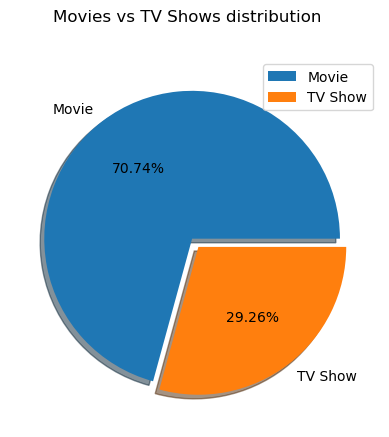

In [69]:
plt.pie(df['type'].value_counts(),labels=df['type'].value_counts().index,autopct='%1.2f%%',
        explode=[0.03,0.04],shadow=True)
plt.suptitle('Movies vs TV Shows distribution')
plt.legend()
plt.show()

In [70]:
df_temp=df_new.drop_duplicates(subset=['country','title'])
df_temp

,title,country,director,cast,genre,type,date_added,release_year,rating,duration,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,unknown,Documentaries,Movie,2021-09-25,2020,teens,90,25,9,2021,September,Saturday
1,Blood & Water,South Africa,unknown,Ama Qamata,International TV Shows,TV Show,2021-09-24,2021,adults,2,24,9,2021,September,Friday
2,Ganglands,unknown,Julien Leclercq,Sami Bouajila,Crime TV Shows,TV Show,2021-09-24,2021,adults,1,24,9,2021,September,Friday
3,Kota Factory,India,unknown,Mayur More,International TV Shows,TV Show,2021-09-24,2021,adults,2,24,9,2021,September,Friday
4,Midnight Mass,unknown,Mike Flanagan,Kate Siegel,TV Dramas,TV Show,2021-09-24,2021,adults,1,24,9,2021,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8520,Zinzana,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas,Movie,2016-03-09,2015,adults,96,9,3,2016,March,Wednesday
8521,Zodiac,United States,David Fincher,Mark Ruffalo,Cult Movies,Movie,2019-11-20,2007,adults,158,20,11,2019,November,Wednesday
8522,Zombieland,United States,Ruben Fleischer,Jesse Eisenberg,Comedies,Movie,2019-11-01,2009,adults,88,1,11,2019,November,Friday
8523,Zoom,United States,Peter Hewitt,Tim Allen,Children & Family Movies,Movie,2020-01-11,2006,kids,88,11,1,2020,January,Saturday


In [71]:
x=df_temp['country'].value_counts().head(10)
x

country
United States     3129
India             1003
unknown            730
United Kingdom     599
Canada             255
Japan              254
France             207
South Korea        203
Spain              177
Mexico             130
Name: count, dtype: int64

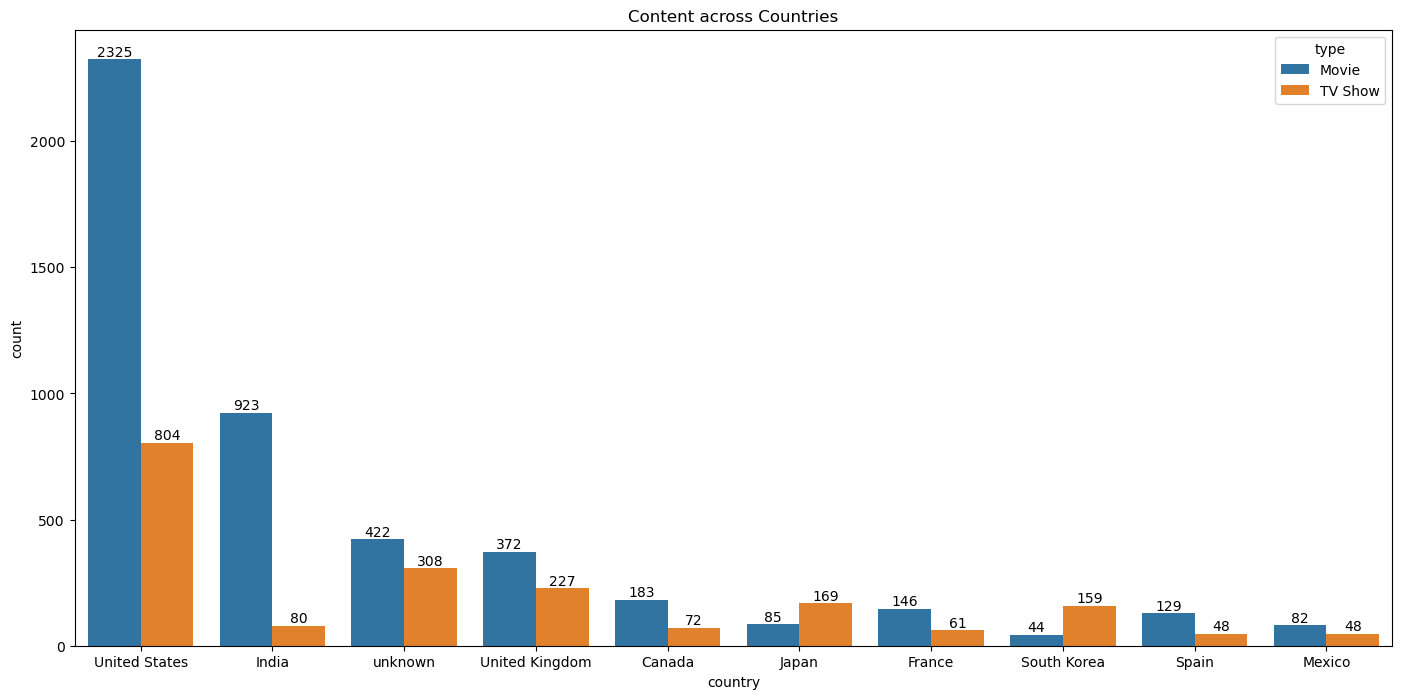

In [72]:
plt.figure(figsize=(17,8))
plt.title('Content across Countries')
label=sns.countplot(data=df_temp,x='country',hue='type',order=x.index)
for i in label.containers:
    label.bar_label(i)
plt.show()

C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\1083132654.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_movies_temp,x='director',order=x.index,palette='plasma')
C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\1083132654.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_tvs_temp,x='director',order=y.index,palette='husl')


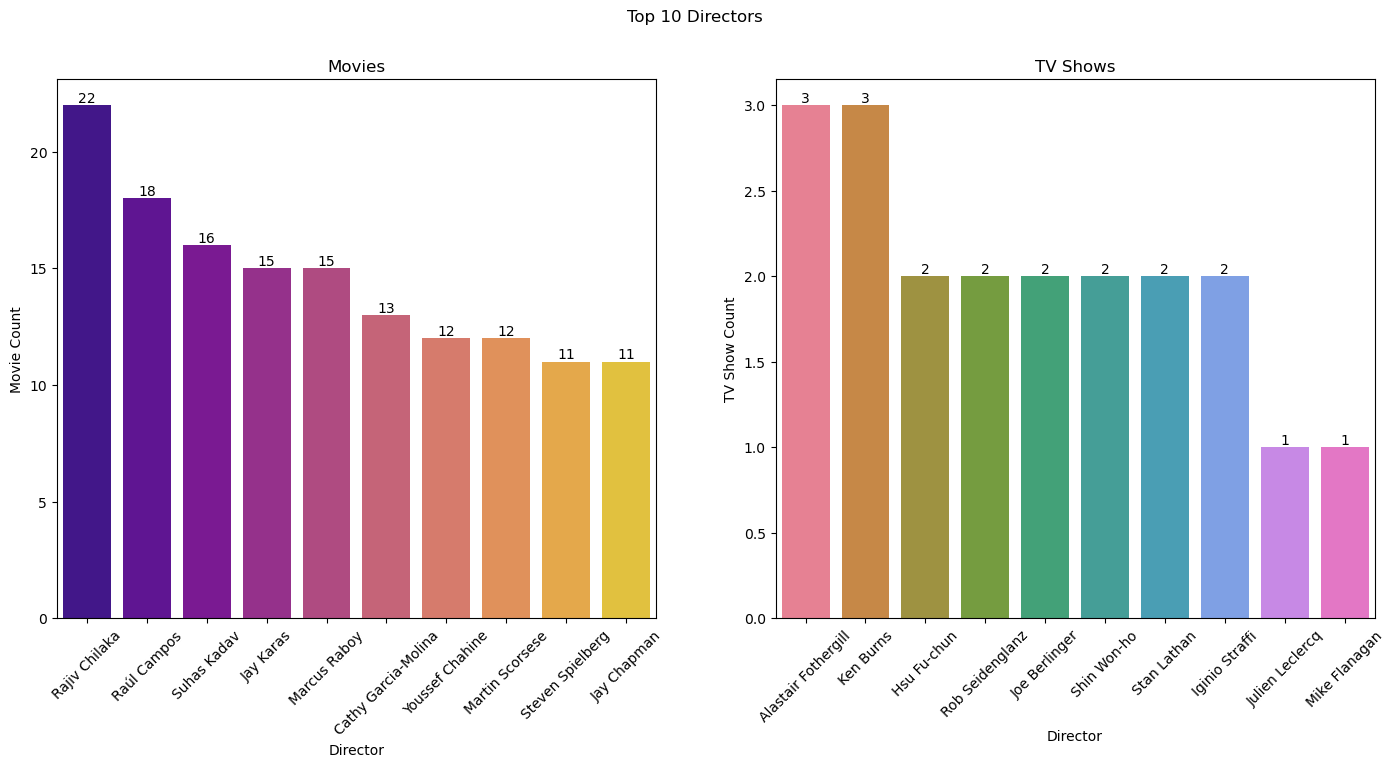

In [73]:
df_movies_temp=df_movies.drop_duplicates(subset=['director','title'])
df_tvs_temp=df_tvs.drop_duplicates(subset=['director','title'])

plt.figure(figsize=(17,7))
plt.suptitle('Top 10 Directors')
plt.subplot(1,2,1)
x=df_movies_temp['director'].value_counts()[1:11]
label=sns.countplot(data=df_movies_temp,x='director',order=x.index,palette='plasma')
for i in label.containers:
    label.bar_label(i)
plt.title('Movies')
plt.xticks(rotation=45)
plt.xlabel('Director')
plt.ylabel('Movie Count')

plt.subplot(1,2,2)
y=df_tvs_temp['director'].value_counts()[1:11]
label=sns.countplot(data=df_tvs_temp,x='director',order=y.index,palette='husl')
for i in label.containers:
    label.bar_label(i)
plt.title('TV Shows')
plt.xticks(rotation=45)
plt.xlabel('Director')
plt.ylabel('TV Show Count')
plt.show()


C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\270467378.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_movies_temp,x='genre',order=x.index,palette='plasma')
C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\270467378.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_tvs_temp,x='genre',order=y.index,palette='viridis')


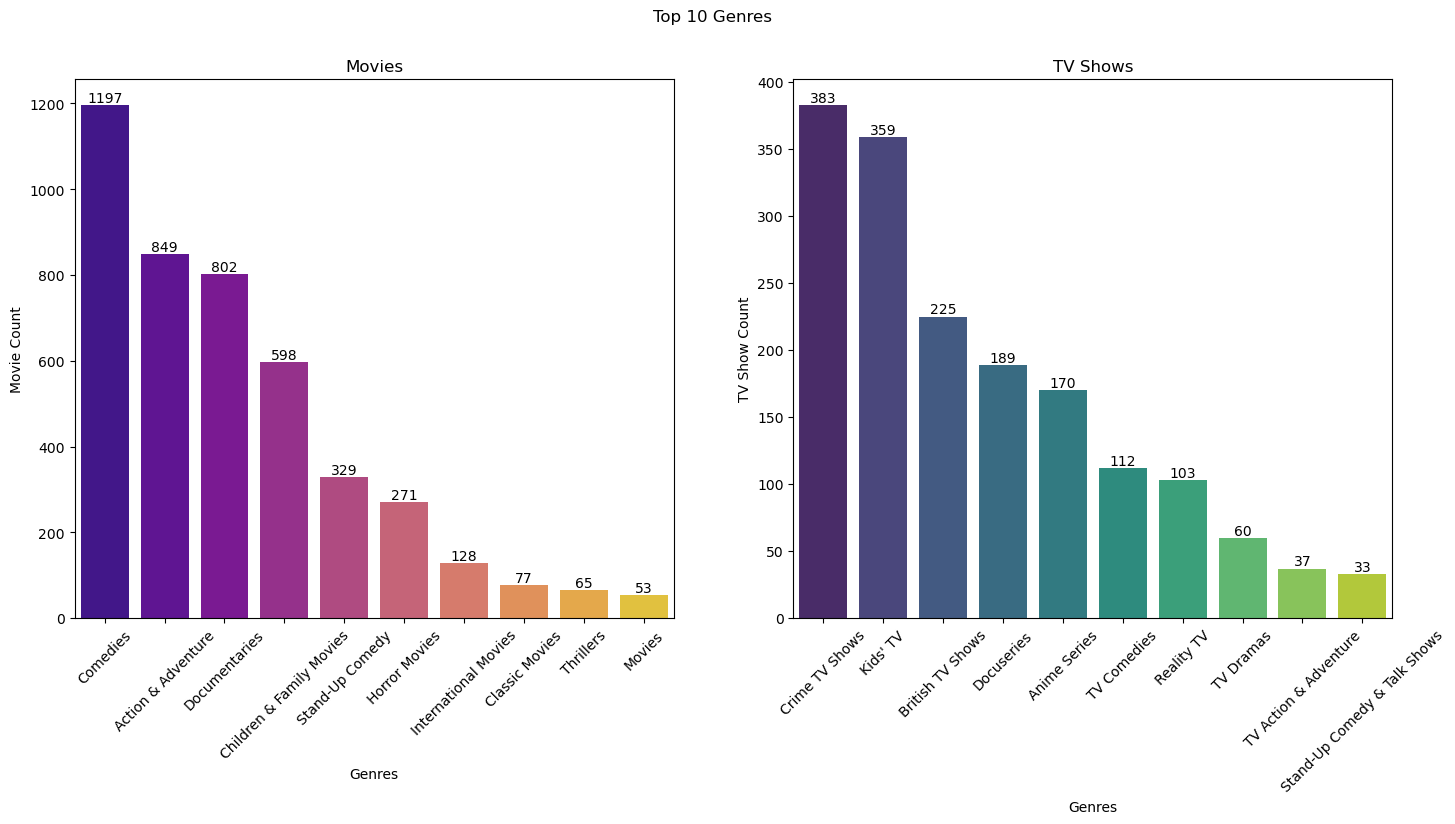

In [74]:
df_movies_temp=df_movies.drop_duplicates(subset=['genre','title'])
df_tvs_temp=df_tvs.drop_duplicates(subset=['genre','title'])

plt.figure(figsize=(17,7))
plt.suptitle('Top 10 Genres')
plt.subplot(1,2,1)
x=df_movies_temp['genre'].value_counts()[1:11]
label=sns.countplot(data=df_movies_temp,x='genre',order=x.index,palette='plasma')
for i in label.containers:
    label.bar_label(i)
plt.title('Movies')
plt.xticks(rotation=45)
plt.xlabel('Genres')
plt.ylabel('Movie Count')

plt.subplot(1,2,2)
y=df_tvs_temp['genre'].value_counts()[1:11]
label=sns.countplot(data=df_tvs_temp,x='genre',order=y.index,palette='viridis')
for i in label.containers:
    label.bar_label(i)
plt.title('TV Shows')
plt.xticks(rotation=45)
plt.xlabel('Genres')
plt.ylabel('TV Show Count')
plt.show()


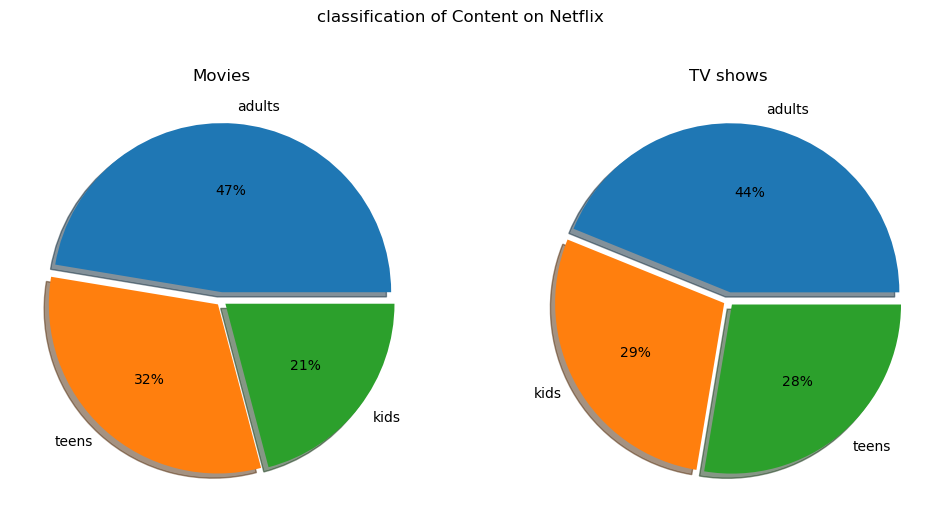

In [75]:
df_movies_temp=df_movies.drop_duplicates(subset=['rating','title'])
df_tvs_temp=df_tvs.drop_duplicates(subset=['rating','title'])


plt.figure(figsize=(12,6))
plt.suptitle('classification of Content on Netflix')

plt.subplot(1,2,1)
plt.pie(df_movies_temp['rating'].value_counts(),
        labels=df_movies_temp['rating'].value_counts().index,
        autopct='%0.0f%%',explode=(0.05,0.03,0.03),shadow=True)
plt.title('Movies')

plt.subplot(1,2,2)
plt.pie(df_tvs_temp['rating'].value_counts(),
        labels=df_tvs_temp['rating'].value_counts().index,
        autopct='%0.0f%%',explode=(0.05,0.03,0.03),shadow=True)
plt.title('TV shows')
plt.show()

In [76]:
df_movies_temp=df_movies.drop_duplicates(subset=['year','title'])
df_movies_temp

,title,country,director,cast,genre,type,date_added,release_year,rating,duration,day,month,year,month_name,weekday
0,Dick Johnson Is Dead,United States,Kirsten Johnson,unknown,Documentaries,Movie,2021-09-25,2020,teens,90,25,9,2021,September,Saturday
5,My Little Pony: A New Generation,unknown,Robert Cullen,Vanessa Hudgens,Children & Family Movies,Movie,2021-09-24,2021,kids,91,24,9,2021,September,Friday
6,Sankofa,United States,Haile Gerima,Kofi Ghanaba,Dramas,Movie,2021-09-24,1993,adults,125,24,9,2021,September,Friday
8,The Starling,United States,Theodore Melfi,Melissa McCarthy,Comedies,Movie,2021-09-24,2021,teens,104,24,9,2021,September,Friday
10,Je Suis Karl,Germany,Christian Schwochow,Luna Wedler,Dramas,Movie,2021-09-23,2021,adults,127,23,9,2021,September,Thursday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8520,Zinzana,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas,Movie,2016-03-09,2015,adults,96,9,3,2016,March,Wednesday
8521,Zodiac,United States,David Fincher,Mark Ruffalo,Cult Movies,Movie,2019-11-20,2007,adults,158,20,11,2019,November,Wednesday
8522,Zombieland,United States,Ruben Fleischer,Jesse Eisenberg,Comedies,Movie,2019-11-01,2009,adults,88,1,11,2019,November,Friday
8523,Zoom,United States,Peter Hewitt,Tim Allen,Children & Family Movies,Movie,2020-01-11,2006,kids,88,11,1,2020,January,Saturday


In [77]:
mv_year=df_movies_temp['year'].value_counts()
mv_year.sort_index(inplace=True)
mv_year

year
2008       1
2009       2
2011      13
2012       3
2013       3
2014      19
2015      51
2016     224
2017     813
2018    1223
2019    1412
2020    1281
2021     986
Name: count, dtype: int64

In [80]:
month_order=['January','February','March','April','May','June','July','August','September','October','November','December']

mv_month=df_movies_temp['month_name'].value_counts().loc[month_order]
mv_month

month_name
January      535
February     375
March        518
April        542
May          433
June         485
July         559
August       515
September    510
October      535
November     489
December     535
Name: count, dtype: int64

In [81]:
day_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
mv_day=df_movies_temp['weekday'].value_counts().loc[day_order]
mv_day

weekday
Monday        612
Tuesday       842
Wednesday     895
Thursday     1040
Friday       1537
Saturday      543
Sunday        562
Name: count, dtype: int64

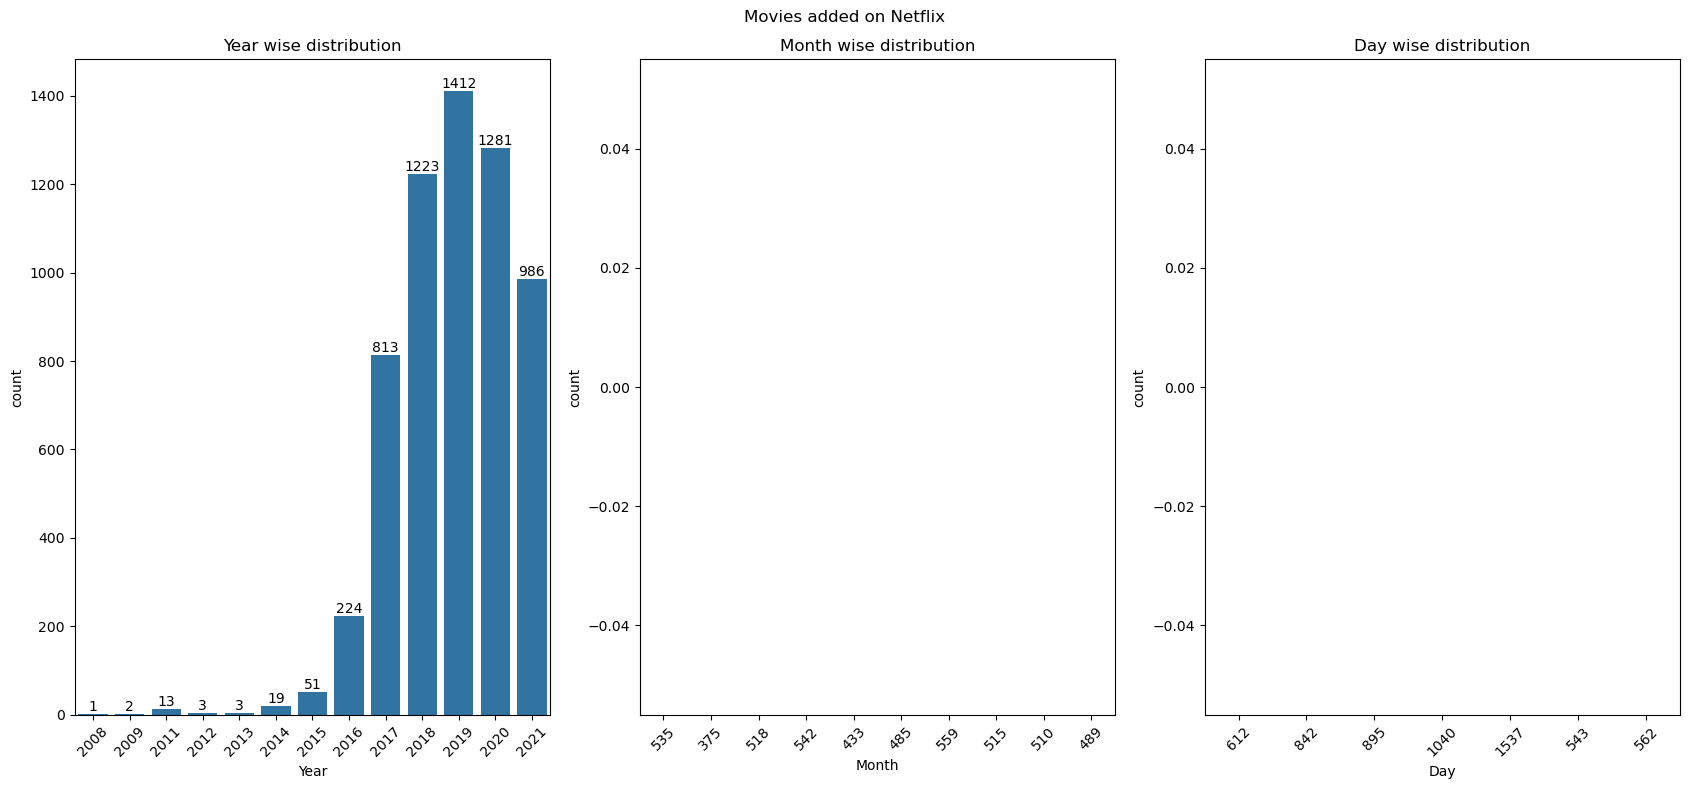

In [82]:
plt.figure(figsize=(17, 8))
plt.suptitle('Movies added on Netflix')

# Year-wise distribution
plt.subplot(1, 3, 1)
label = sns.countplot(data=df_movies_temp, x='year', order=mv_year.index)

for i in label.containers:
    label.bar_label(i)

plt.xticks(rotation=45)
plt.xlabel('Year')
plt.title('Year wise distribution')

# Month-wise distribution
plt.subplot(1, 3, 2)
label = sns.countplot(data=df_movies_temp, x='month_name', order=mv_month)

for i in label.containers:
    label.bar_label(i)

plt.xticks(rotation=45)
plt.xlabel('Month')
plt.title('Month wise distribution')

# Day-wise distribution
plt.subplot(1, 3, 3)
label = sns.countplot(data=df_movies_temp, x='weekday', order=mv_day)

for i in label.containers:
    label.bar_label(i)

plt.xticks(rotation=45)
plt.xlabel('Day')
plt.title('Day wise distribution')

plt.tight_layout()
plt.show()

C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\3603528632.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_tvs_temp,x='year',order=tv_year.index,palette='husl')
C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\3603528632.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_tvs_temp,x='month_name',order=tv_month.index,palette='plasma')
C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\3603528632.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_tvs_temp,x='weekday',order=tv_w

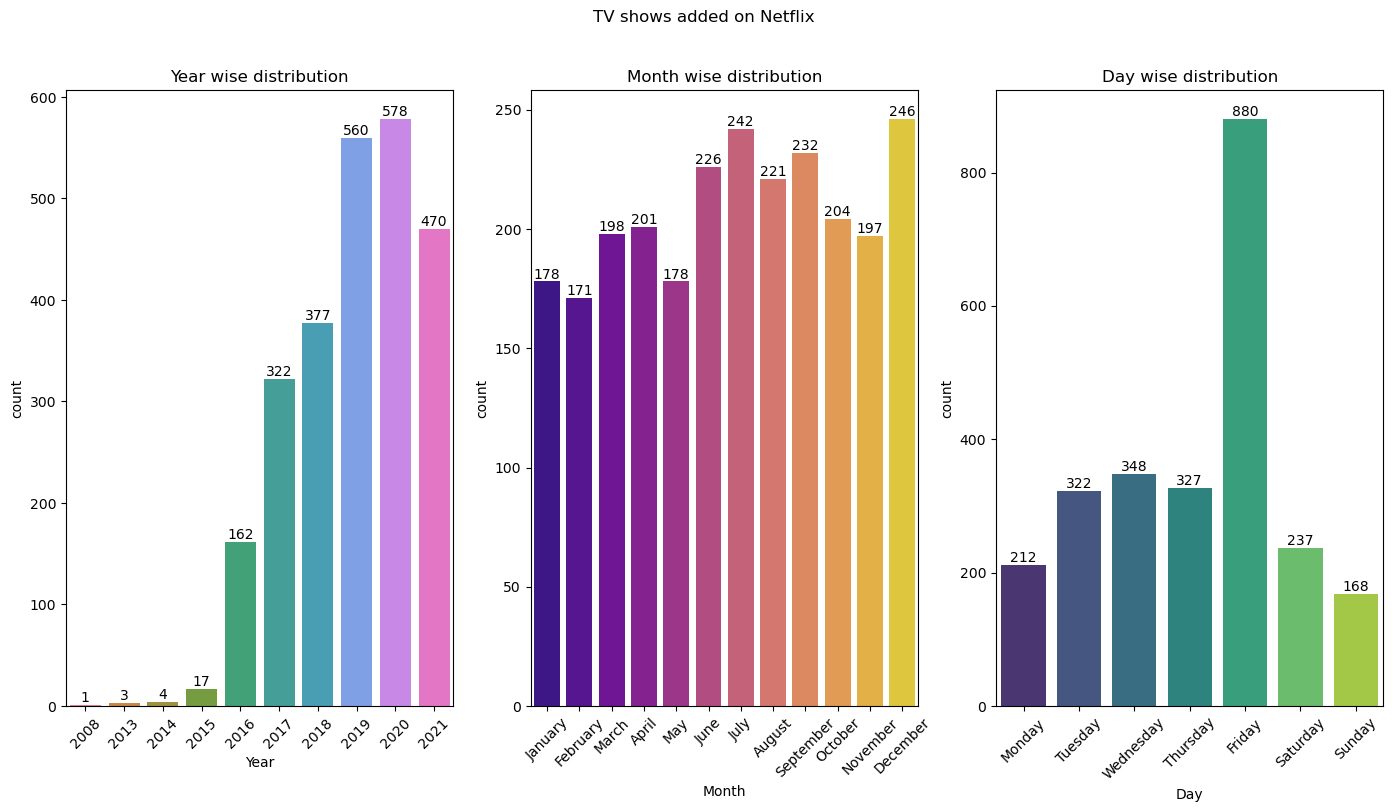

In [83]:
df_tvs_temp=df_tvs.drop_duplicates(subset=['year','title'])

tv_year=df_tvs_temp['year'].value_counts()
tv_year.sort_index(inplace=True)

month_order=['January','February','March','April','May','June','July','August','September','October','November','December']
tv_month=df_tvs_temp['month_name'].value_counts().loc[month_order]

day_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
tv_weekday=df_movies_temp['weekday'].value_counts().loc[day_order]

plt.figure(figsize=(17,8))
plt.suptitle('TV shows added on Netflix')

plt.subplot(1,3,1)
label=sns.countplot(data=df_tvs_temp,x='year',order=tv_year.index,palette='husl')
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.title('Year wise distribution')

plt.subplot(1,3,2)
label=sns.countplot(data=df_tvs_temp,x='month_name',order=tv_month.index,palette='plasma')
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.title('Month wise distribution')

plt.subplot(1,3,3)
label=sns.countplot(data=df_tvs_temp,x='weekday',order=tv_weekday.index,palette='viridis')
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Day')
plt.title('Day wise distribution')
plt.show()

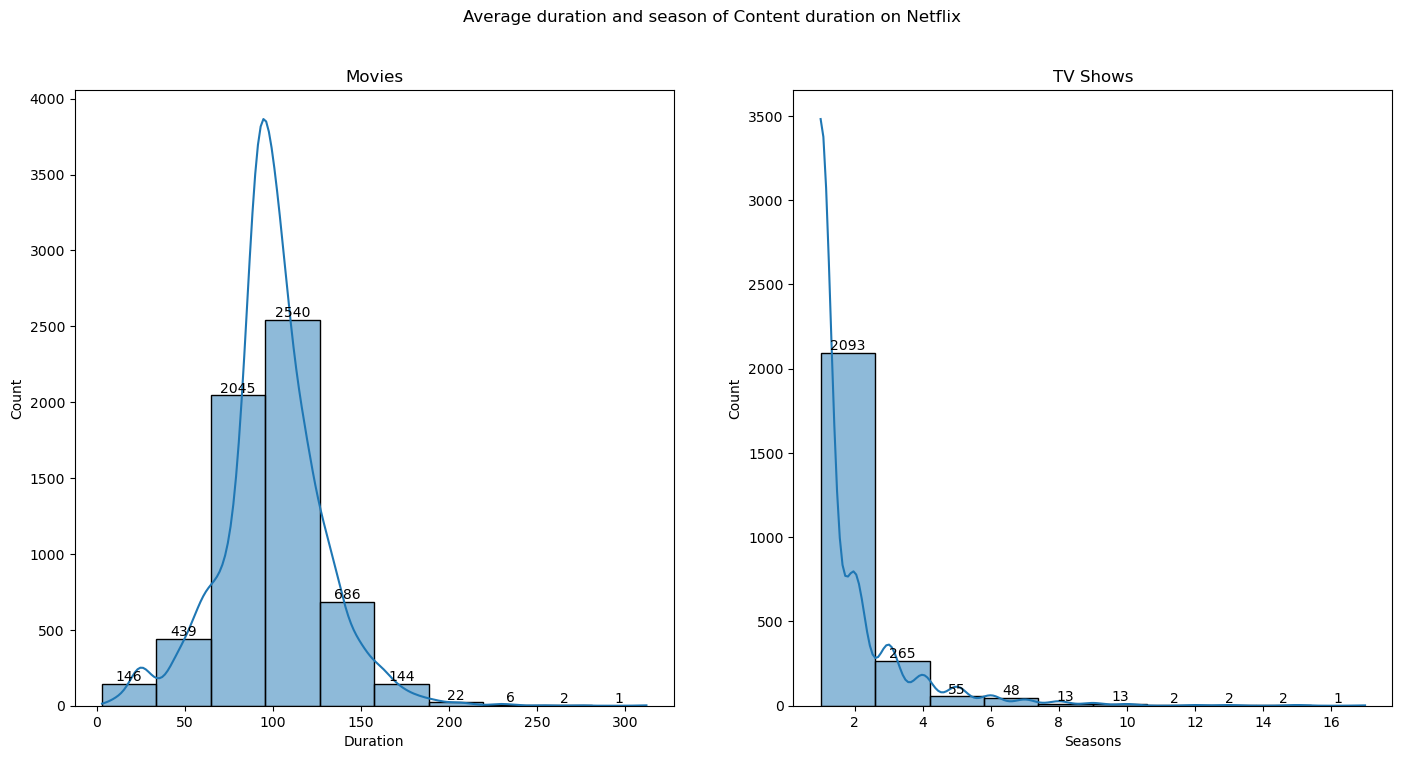

In [84]:
df_movies_temp=df_movies.drop_duplicates(subset=['duration','title'])
df_tvs_temp=df_tvs.drop_duplicates(subset=['seasons','title'])

plt.figure(figsize=(17,8))
plt.suptitle('Average duration and season of Content duration on Netflix')

plt.subplot(1,2,1)
label=sns.histplot(df_movies_temp['duration'],bins=10,kde=True)
for i in label.containers:
    label.bar_label(i)
plt.xlabel('Duration')
plt.title('Movies')

plt.subplot(1,2,2)
label=sns.histplot(data=df_tvs_temp,x='seasons',bins=10,kde=True)
for i in label.containers:
    label.bar_label(i)
plt.xlabel('Seasons')
plt.title('TV Shows')
plt.show()

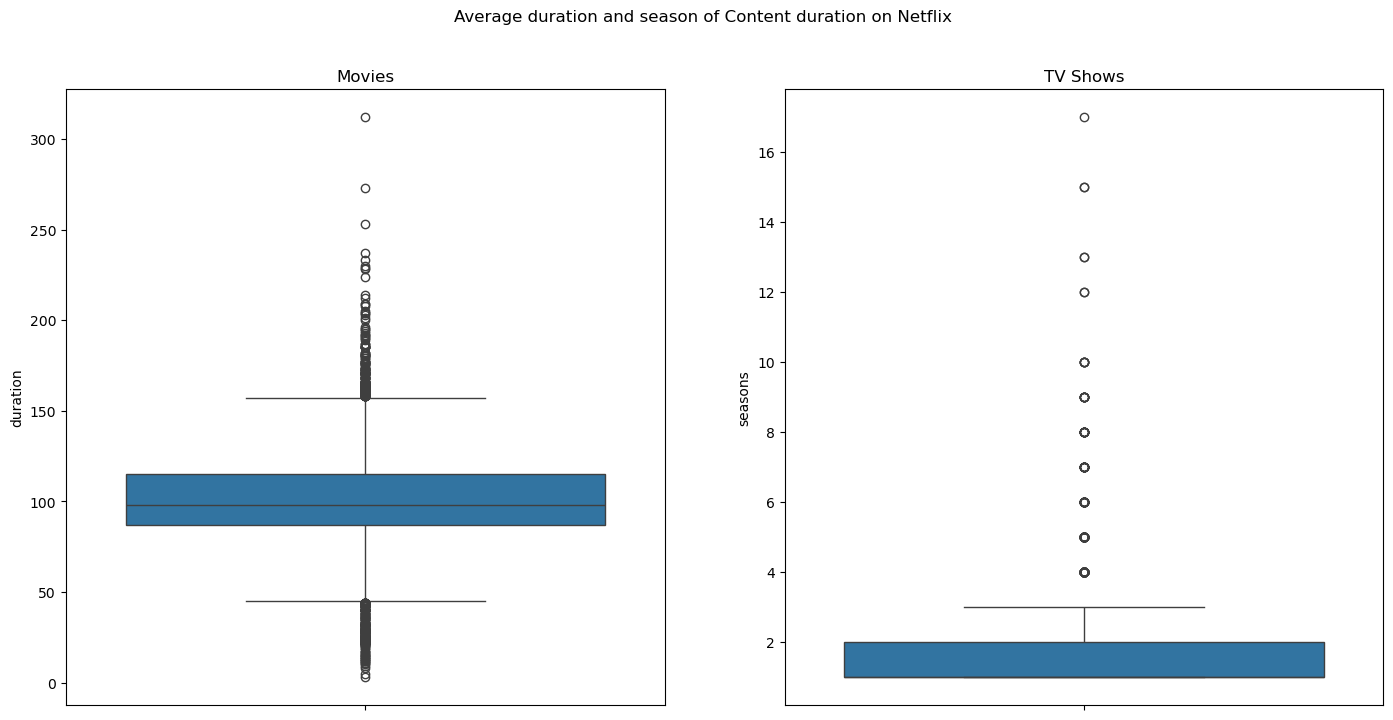

In [85]:
plt.figure(figsize=(17,8))
plt.suptitle('Average duration and season of Content duration on Netflix')

plt.subplot(1,2,1)
sns.boxplot(y=df_movies_temp['duration'])
plt.title('Movies')

plt.subplot(1,2,2)
sns.boxplot(y=df_tvs_temp['seasons'])
plt.title('TV Shows')
plt.show()

C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\3094110487.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_movies_temp,x='cast',order=x.index,palette='plasma')
C:\Users\DEE YADAV\AppData\Local\Temp\ipykernel_5348\3094110487.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label=sns.countplot(data=df_tvs_temp,x='cast',order=y.index,palette='viridis')


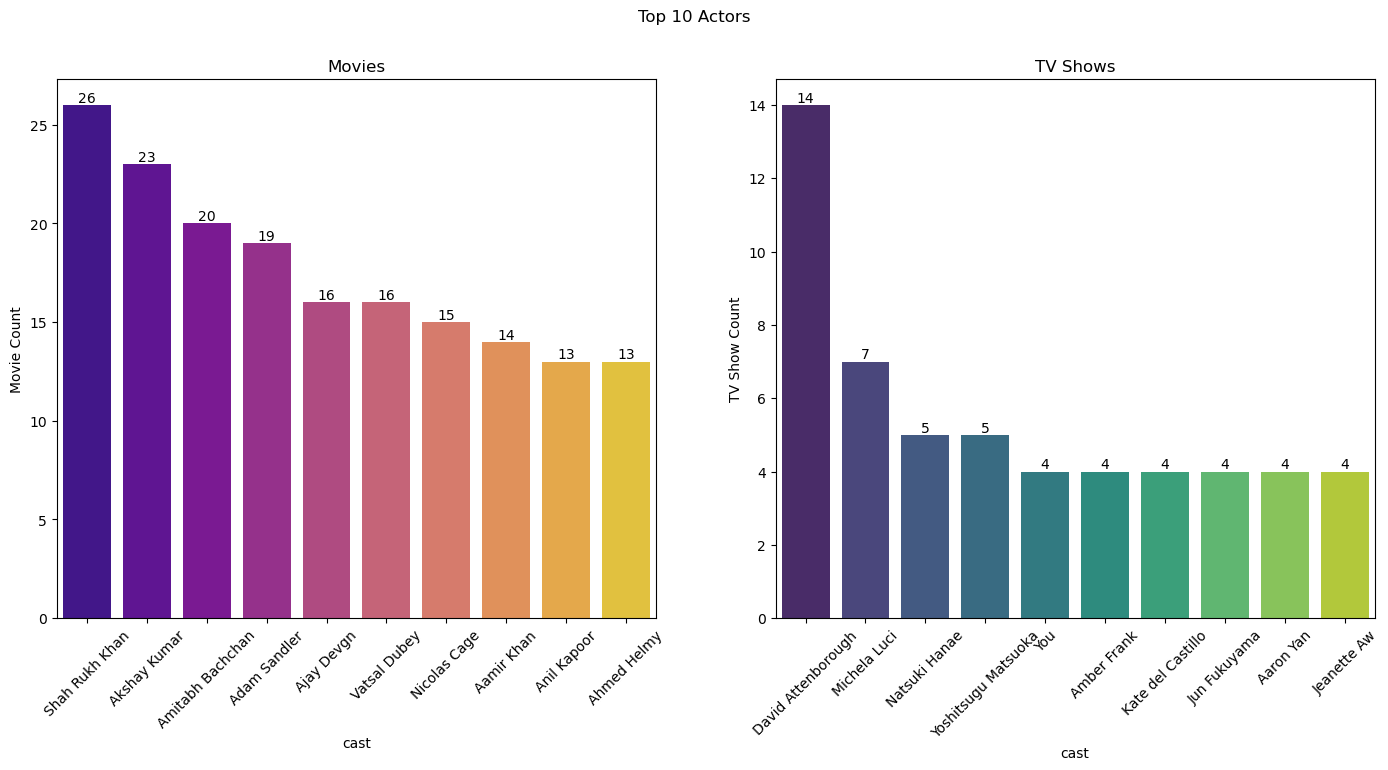

In [86]:
df_movies_temp=df_movies.drop_duplicates(subset=['cast','title'])
df_tvs_temp=df_tvs.drop_duplicates(subset=['cast','title'])

plt.figure(figsize=(17,7))
plt.suptitle('Top 10 Actors')
plt.subplot(1,2,1)
x=df_movies_temp['cast'].value_counts()[1:11]
label=sns.countplot(data=df_movies_temp,x='cast',order=x.index,palette='plasma')
for i in label.containers:
    label.bar_label(i)
plt.title('Movies')
plt.xticks(rotation=45)
plt.xlabel('cast')
plt.ylabel('Movie Count')

plt.subplot(1,2,2)
y=df_tvs_temp['cast'].value_counts()[1:11]
label=sns.countplot(data=df_tvs_temp,x='cast',order=y.index,palette='viridis')
for i in label.containers:
    label.bar_label(i)
plt.title('TV Shows')
plt.xticks(rotation=45)
plt.xlabel('cast')
plt.ylabel('TV Show Count')
plt.show()